# Comprehensive Data Preprocessing and Visualization

## Objectives
- Inspect the quality and structure of the original dataset.
- Standardize categorical values.
- Investigate zero values and extreme observations.
- Visualize numerical distributions before and after appropriate transformations.
- Document cleaning decisions and generate a reproducible cleaned dataset.
- Preserve the original dataset for traceability.

In [2]:
# 1. Load the original dataset and create a working copy

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

# Support running from either the project root or notebooks folder
if (PROJECT_ROOT / "data" / "crop_yield.csv").exists():
    DATA_PATH = PROJECT_ROOT / "data" / "crop_yield.csv"
    OUTPUT_DIR = PROJECT_ROOT / "docs" / "preprocessing"
elif (PROJECT_ROOT.parent / "data" / "crop_yield.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
    DATA_PATH = PROJECT_ROOT / "data" / "crop_yield.csv"
    OUTPUT_DIR = PROJECT_ROOT / "docs" / "preprocessing"
else:
    raise FileNotFoundError("Could not locate data/crop_yield.csv")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_original = pd.read_csv(DATA_PATH)
df_working = df_original.copy(deep=True)

print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_working.shape)
print("Original CSV:", DATA_PATH)
print("Output directory:", OUTPUT_DIR)
print("Original data preserved:", df_original.equals(df_working))

Original dataset shape: (19689, 10)
Working dataset shape: (19689, 10)
Original CSV: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\data\crop_yield.csv
Output directory: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\preprocessing
Original data preserved: True


In [3]:
# 2. Initial data-quality audit

text_columns = ["Crop", "Season", "State"]
numeric_columns = df_working.select_dtypes(include="number").columns.tolist()

quality_report = pd.DataFrame({
    "Data Type": df_working.dtypes.astype(str),
    "Missing Values": df_working.isna().sum(),
    "Unique Values": df_working.nunique(),
})

print("DATASET QUALITY REPORT")
display(quality_report)

print("\nExact duplicate rows:", df_working.duplicated().sum())

print("\nNegative values in numerical columns:")
display((df_working[numeric_columns] < 0).sum().rename("Negative Count").to_frame())

print("\nZero values in important columns:")
display(
    (df_working[["Area", "Production", "Annual_Rainfall",
                 "Fertilizer", "Pesticide", "Yield"]] == 0)
    .sum()
    .rename("Zero Count")
    .to_frame()
)

print("\nOriginal categorical labels:")
for col in text_columns:
    print(f"\n{col}: {df_working[col].nunique()} unique values")
    print(df_working[col].value_counts().head(10))

DATASET QUALITY REPORT


,Data Type,Missing Values,Unique Values
Crop,str,0,55
Crop_Year,int64,0,24
Season,str,0,6
State,str,0,30
Area,float64,0,13644
Production,int64,0,14016
Annual_Rainfall,float64,0,634
Fertilizer,float64,0,18598
Pesticide,float64,0,17405
Yield,float64,0,13551



Exact duplicate rows: 0

Negative values in numerical columns:


,Negative Count
Crop_Year,0
Area,0
Production,0
Annual_Rainfall,0
Fertilizer,0
Pesticide,0
Yield,0



Zero values in important columns:


,Zero Count
Area,0
Production,112
Annual_Rainfall,0
Fertilizer,0
Pesticide,0
Yield,112



Original categorical labels:

Crop: 55 unique values
Crop
Rice                 1197
Maize                 975
Moong(Green Gram)     740
Urad                  733
Groundnut             725
Sesamum               685
Potato                628
Sugarcane             605
Wheat                 545
Rapeseed &Mustard     528
Name: count, dtype: int64

Season: 6 unique values
Season
Kharif         8232
Rabi           5742
Whole Year     3717
Summer         1195
Autumn          414
Winter          389
Name: count, dtype: int64

State: 30 unique values
State
Karnataka         1432
Andhra Pradesh    1266
West Bengal       1094
Chhattisgarh       915
Bihar              896
Madhya Pradesh     845
Uttar Pradesh      825
Tamil Nadu         822
Gujarat            817
Maharashtra        770
Name: count, dtype: int64


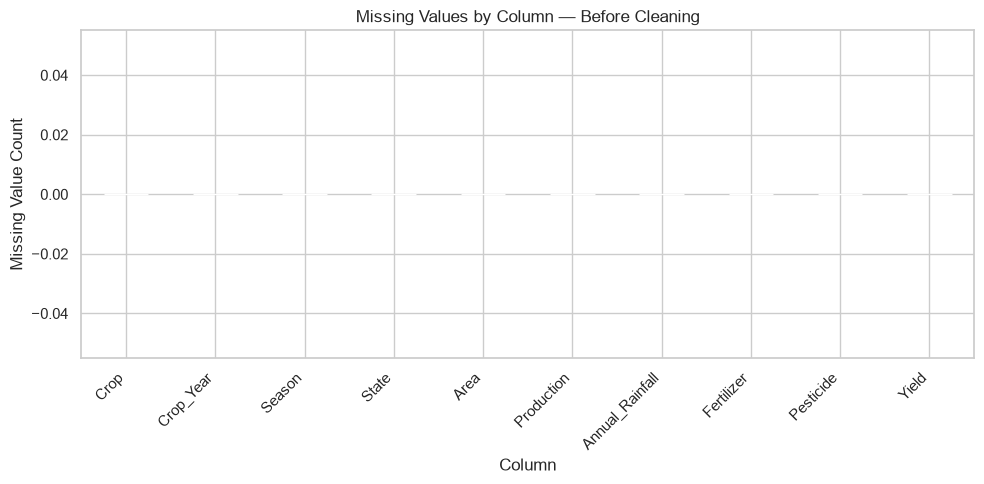

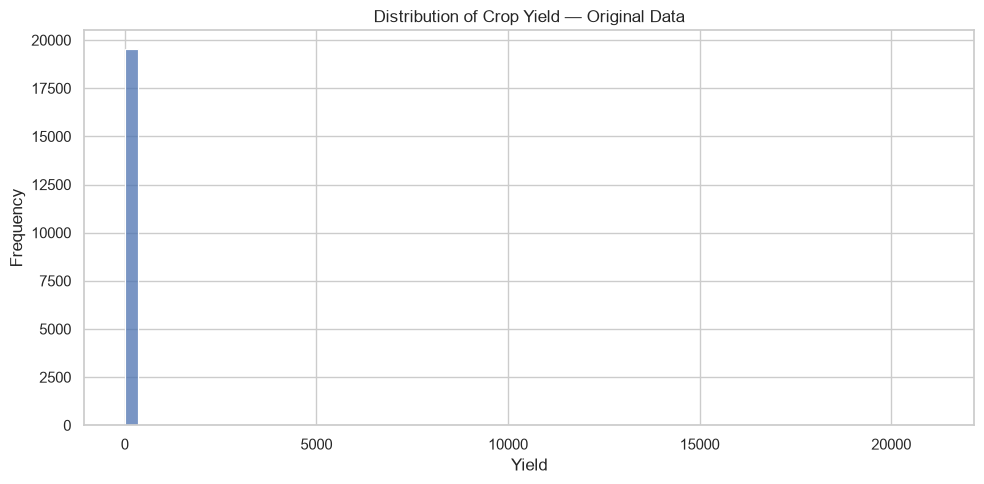

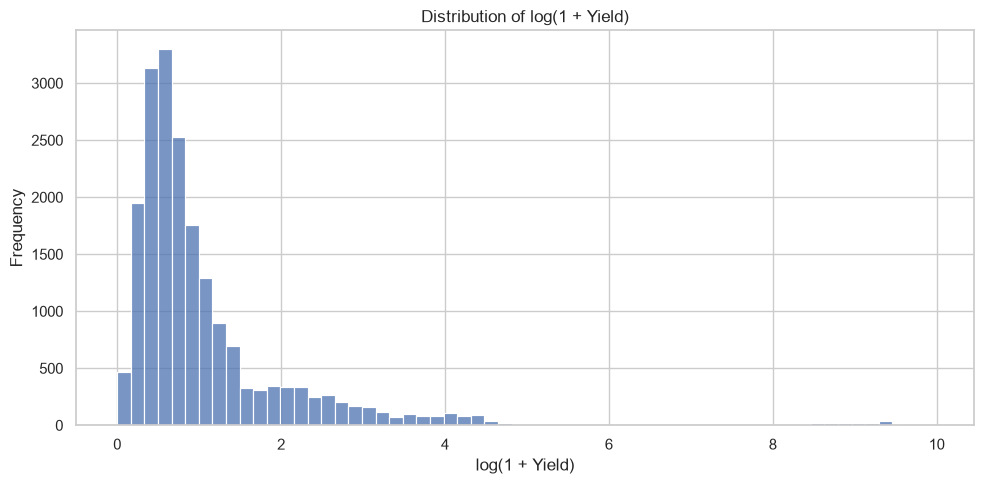

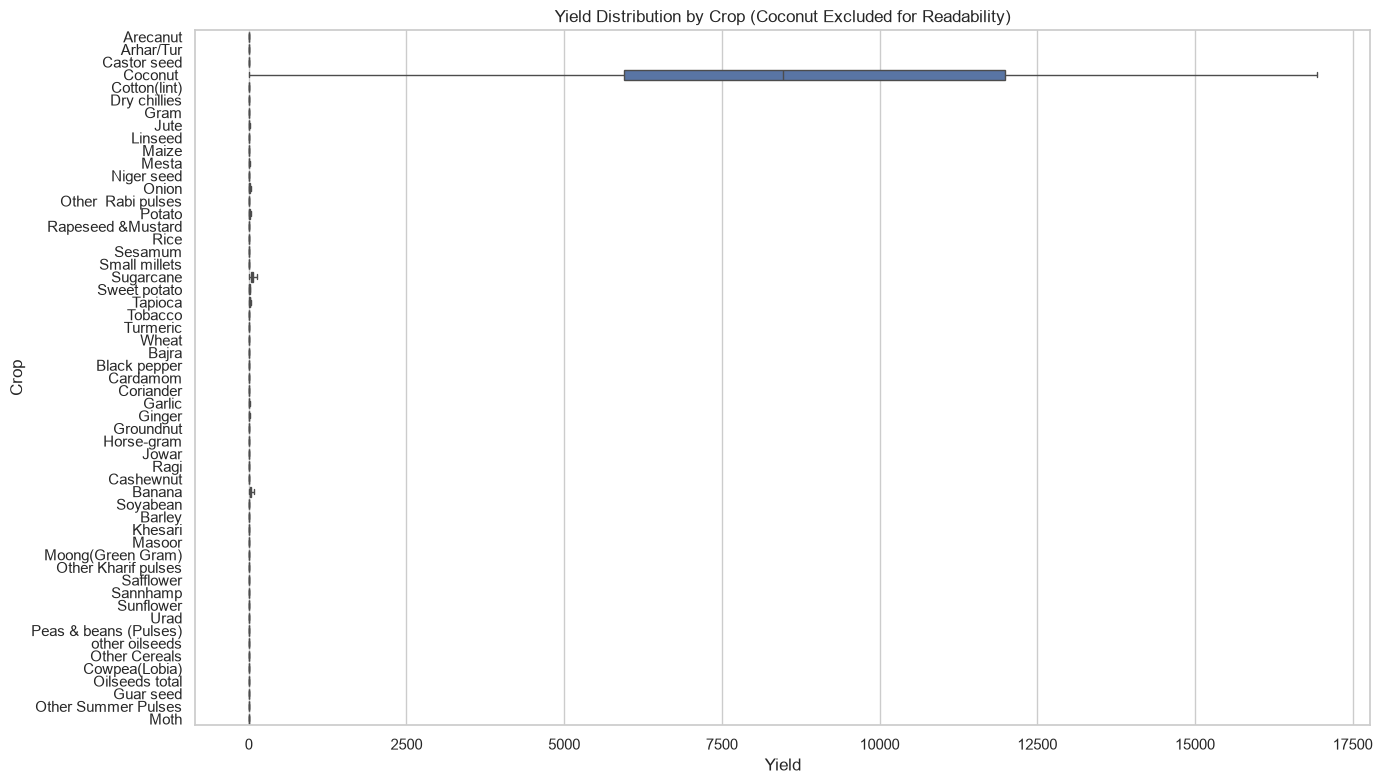

Charts saved to: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\preprocessing


In [4]:
# 3. Initial data exploration visualizations

sns.set_theme(style="whitegrid")

# Chart 1: Missing values by column
missing = df_original.isna().sum()

plt.figure(figsize=(10, 5))
missing.sort_values().plot(kind="bar")
plt.title("Missing Values by Column — Before Cleaning")
plt.xlabel("Column")
plt.ylabel("Missing Value Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_missing_values.png", dpi=200)
plt.show()

# Chart 2: Distribution of yield
plt.figure(figsize=(10, 5))
sns.histplot(df_original["Yield"], bins=60, kde=False)
plt.title("Distribution of Crop Yield — Original Data")
plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_yield_distribution.png", dpi=200)
plt.show()

# Chart 3: Yield distribution on a log scale
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df_original["Yield"]), bins=60, kde=False)
plt.title("Distribution of log(1 + Yield)")
plt.xlabel("log(1 + Yield)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_log_yield_distribution.png", dpi=200)
plt.show()

# Chart 4: Yield by crop, excluding Coconut for readability
# This is a visualization choice only; no records are deleted.
plot_data = df_original[df_original["Crop"] != "Coconut"]

plt.figure(figsize=(14, 8))
sns.boxplot(data=plot_data, x="Yield", y="Crop", showfliers=False)
plt.title("Yield Distribution by Crop (Coconut Excluded for Readability)")
plt.xlabel("Yield")
plt.ylabel("Crop")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_yield_by_crop.png", dpi=200)
plt.show()

print("Charts saved to:", OUTPUT_DIR)

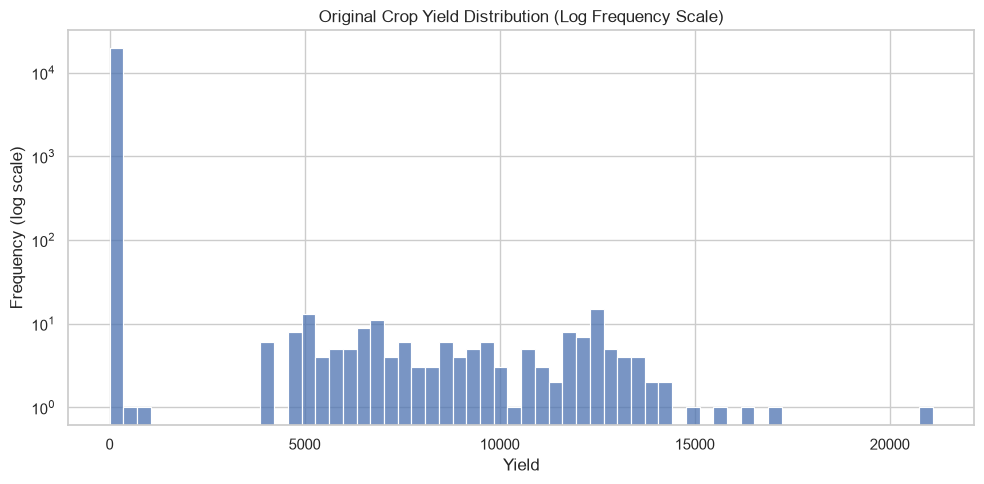

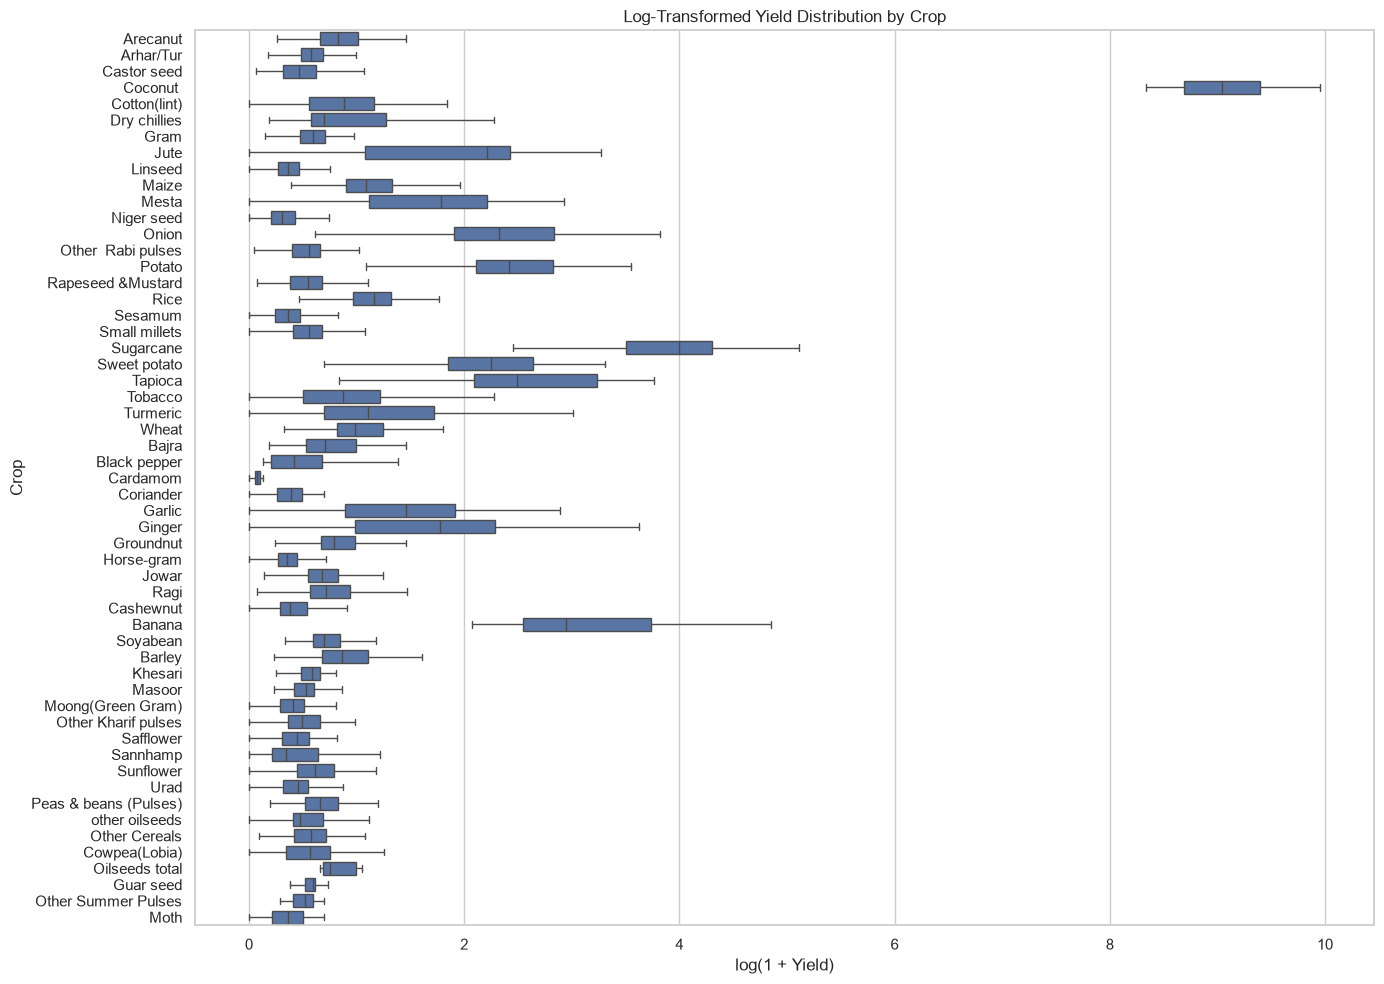

In [5]:
# 4. Improved visualizations for skewed yield data

# Original yield with a logarithmic frequency axis
plt.figure(figsize=(10, 5))
sns.histplot(df_original["Yield"], bins=60)
plt.yscale("log")
plt.title("Original Crop Yield Distribution (Log Frequency Scale)")
plt.xlabel("Yield")
plt.ylabel("Frequency (log scale)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_yield_log_frequency.png", dpi=200)
plt.show()

# Crop-wise distribution using a logarithmic yield axis
# log1p allows zero-yield records to remain visible.
plot_df = df_original.copy()
plot_df["Log_Yield"] = np.log1p(plot_df["Yield"])

plt.figure(figsize=(14, 10))
sns.boxplot(data=plot_df, x="Log_Yield", y="Crop", showfliers=False)
plt.title("Log-Transformed Yield Distribution by Crop")
plt.xlabel("log(1 + Yield)")
plt.ylabel("Crop")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_log_yield_by_crop.png", dpi=200)
plt.show()

In [6]:
# 5. Standardize categorical text

df_cleaned = df_original.copy(deep=True)

text_columns = ["Crop", "Season", "State"]

category_audit = []

for col in text_columns:
    before_unique = df_cleaned[col].nunique()
    before_whitespace = (
        df_cleaned[col]
        .astype("string")
        .ne(df_cleaned[col].astype("string").str.strip())
        .sum()
    )

    # Remove leading/trailing whitespace
    df_cleaned[col] = df_cleaned[col].astype("string").str.strip()

    after_unique = df_cleaned[col].nunique()

    category_audit.append({
        "Column": col,
        "Unique Before": before_unique,
        "Unique After": after_unique,
        "Values With Whitespace": int(before_whitespace),
        "Rows Changed": int(
            df_original[col].astype("string").ne(df_cleaned[col]).sum()
        )
    })

category_audit = pd.DataFrame(category_audit)

print("CATEGORICAL CLEANING SUMMARY")
display(category_audit)

print("Shape before:", df_original.shape)
print("Shape after:", df_cleaned.shape)
print("Missing values after cleaning:")
display(df_cleaned.isna().sum().to_frame("Missing Values"))

print("Exact duplicate rows after text cleaning:",
      df_cleaned.duplicated().sum())

CATEGORICAL CLEANING SUMMARY


,Column,Unique Before,Unique After,Values With Whitespace,Rows Changed
0,Crop,55,55,172,172
1,Season,6,6,19689,19689
2,State,30,30,0,0


Shape before: (19689, 10)
Shape after: (19689, 10)
Missing values after cleaning:


,Missing Values
Crop,0
Crop_Year,0
Season,0
State,0
Area,0
Production,0
Annual_Rainfall,0
Fertilizer,0
Pesticide,0
Yield,0


Exact duplicate rows after text cleaning: 0


In [7]:
# 6. Investigate zero-production and zero-yield records

zero_production = df_cleaned["Production"].eq(0)
zero_yield = df_cleaned["Yield"].eq(0)

zero_summary = pd.DataFrame({
    "Condition": [
        "Production = 0",
        "Yield = 0",
        "Both Production and Yield = 0",
        "Production = 0 but Yield > 0",
        "Production > 0 but Yield = 0",
    ],
    "Records": [
        int(zero_production.sum()),
        int(zero_yield.sum()),
        int((zero_production & zero_yield).sum()),
        int((zero_production & df_cleaned["Yield"].gt(0)).sum()),
        int((df_cleaned["Production"].gt(0) & zero_yield).sum()),
    ]
})

display(zero_summary)

print("\nZero-production records by crop:")
display(
    df_cleaned.loc[zero_production]
    .groupby("Crop")
    .size()
    .sort_values(ascending=False)
    .head(15)
    .rename("Records")
    .to_frame()
)

print("\nZero-production records by year:")
display(
    df_cleaned.loc[zero_production]
    .groupby("Crop_Year")
    .size()
    .rename("Records")
    .to_frame()
)

print("\nSample records requiring investigation:")
display(
    df_cleaned.loc[zero_production, [
        "Crop", "Crop_Year", "Season", "State",
        "Area", "Production", "Yield"
    ]].head(15)
)

,Condition,Records
0,Production = 0,112
1,Yield = 0,112
2,Both Production and Yield = 0,108
3,Production = 0 but Yield > 0,4
4,Production > 0 but Yield = 0,4



Zero-production records by crop:


,Records
Crop,
Jute,15
Coconut,7
Horse-gram,7
Sannhamp,7
Onion,7
Moong(Green Gram),6
Sweet potato,5
Soyabean,4
Tobacco,4



Zero-production records by year:


,Records
Crop_Year,
1999,2
2000,3
2001,3
2002,5
2003,4
2004,3
2005,7
2006,2
2008,1



Sample records requiring investigation:


,Crop,Crop_Year,Season,State,Area,Production,Yield
1058,Soyabean,2002,Kharif,Andhra Pradesh,41284.0,0,0.0
1134,other oilseeds,2002,Whole Year,Kerala,2253.0,0,0.0
1135,Arecanut,2002,Whole Year,Tamil Nadu,4956.0,0,0.0
1273,other oilseeds,2003,Rabi,Andhra Pradesh,14609.0,0,0.0
1441,Arecanut,2003,Whole Year,Tamil Nadu,5219.0,0,0.0
1651,Niger seed,2004,Kharif,Tamil Nadu,1239.0,0,0.0
1678,Garlic,2005,Whole Year,Andhra Pradesh,800.0,0,0.0
1883,Maize,2005,Kharif,Tamil Nadu,202830.0,0,0.0
1884,Mesta,2005,Kharif,Tamil Nadu,1.0,0,0.0
1886,Niger seed,2005,Kharif,Tamil Nadu,638.0,0,0.0


In [8]:
# 7. Inspect records where Production and Yield disagree on zero status

inconsistent_records = df_cleaned[
    (df_cleaned["Production"].eq(0) & df_cleaned["Yield"].gt(0))
    | (df_cleaned["Production"].gt(0) & df_cleaned["Yield"].eq(0))
].copy()

print("Inconsistent records:", len(inconsistent_records))

display(
    inconsistent_records[
        [
            "Crop", "Crop_Year", "Season", "State",
            "Area", "Production", "Yield"
        ]
    ].sort_values(["Crop", "Crop_Year"])
)

# Save a separate review file; do not change the main dataset.
review_path = OUTPUT_DIR / "zero_value_records_for_review.csv"
inconsistent_records.to_csv(review_path, index=False)

print("\nReview records saved to:", review_path)
print("Main dataset unchanged:", df_cleaned.shape == df_original.shape)

Inconsistent records: 8


,Crop,Crop_Year,Season,State,Area,Production,Yield
92,Cardamom,1997,Whole Year,West Bengal,2674.0,7,0.0
5371,Cotton(lint),2017,Kharif,Tamil Nadu,138290.0,337,0.0
5372,Cotton(lint),2017,Rabi,Tamil Nadu,43341.0,101,0.0
18226,Horse-gram,2016,Rabi,Jammu and Kashmir,1.0,0,0.4
18948,Masoor,2004,Kharif,Mizoram,0.5,0,0.4
125,Sunflower,1997,Whole Year,West Bengal,278.0,1,0.0
18005,Tobacco,2012,Kharif,Jammu and Kashmir,1.0,0,0.4
18122,Tobacco,2014,Kharif,Jammu and Kashmir,1.0,0,0.4



Review records saved to: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\preprocessing\zero_value_records_for_review.csv
Main dataset unchanged: True


In [9]:
# 8. Crop-wise IQR outlier analysis

outlier_frames = []

for crop, group in df_cleaned.groupby("Crop"):
    q1 = group["Yield"].quantile(0.25)
    q3 = group["Yield"].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    flagged = group[
        (group["Yield"] < lower_bound)
        | (group["Yield"] > upper_bound)
    ].copy()

    if not flagged.empty:
        flagged["Lower_Bound"] = lower_bound
        flagged["Upper_Bound"] = upper_bound
        outlier_frames.append(flagged)

if outlier_frames:
    outlier_records = pd.concat(outlier_frames).sort_values(
        "Yield", ascending=False
    )
else:
    outlier_records = pd.DataFrame()

print("Total IQR-flagged records:", len(outlier_records))

print("\nCrops with the most flagged records:")
if not outlier_records.empty:
    display(
        outlier_records.groupby("Crop")
        .size()
        .sort_values(ascending=False)
        .head(15)
        .rename("Flagged Records")
        .to_frame()
    )

    print("\nTop 15 highest-yield flagged records:")
    display(
        outlier_records.nlargest(15, "Yield")[
            ["Crop", "Crop_Year", "Season", "State",
             "Area", "Production", "Yield",
             "Lower_Bound", "Upper_Bound"]
        ]
    )

    outlier_path = OUTPUT_DIR / "crop_wise_iqr_outliers.csv"
    outlier_records.to_csv(outlier_path, index=False)
    print("\nOutlier review file saved to:", outlier_path)

print("\nNo rows have been removed.")


Total IQR-flagged records: 749

Crops with the most flagged records:


,Flagged Records
Crop,
Maize,62
Wheat,40
Dry chillies,36
Sannhamp,35
Groundnut,34
Tobacco,33
Peas & beans (Pulses),27
Turmeric,24
Arhar/Tur,24



Top 15 highest-yield flagged records:


,Crop,Crop_Year,Season,State,Area,Production,Yield,Lower_Bound,Upper_Bound
13962,Coconut,2014,Whole Year,Telangana,439.0,9265095,21105.000000,-3103.714598,21033.775759
6259,Maize,1997,Autumn,Maharashtra,21.0,19695,989.870000,-0.489777,4.733676
5104,Onion,2017,Kharif,Andhra Pradesh,17336.0,662728,381.420000,-9.797369,31.593481
2722,Cashewnut,2008,Whole Year,Tamil Nadu,99168.0,51667,338.548966,-0.226888,1.275406
17906,Potato,2010,Whole Year,Delhi,51.0,15862,311.020000,-5.724728,28.826837
17915,Potato,2011,Whole Year,Delhi,48.0,14928,311.000000,-5.724728,28.826837
17861,Potato,2009,Whole Year,Delhi,88.0,21999,249.990000,-5.724728,28.826837
5452,Onion,2018,Kharif,Andhra Pradesh,24750.0,677050,247.572727,-9.797369,31.593481
10659,Onion,2008,Whole Year,Haryana,2492.0,37400,178.653077,-9.797369,31.593481
18152,Sugarcane,2014,Kharif,Puducherry,1921.0,316965,165.000000,-29.151724,134.691034



Outlier review file saved to: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\preprocessing\crop_wise_iqr_outliers.csv

No rows have been removed.


In [10]:
# 9. Investigate the largest crop-wise IQR outliers

outlier_check = outlier_records.copy()

outlier_check["Calculated_Yield"] = (
    outlier_check["Production"] / outlier_check["Area"]
)

outlier_check["Absolute_Difference"] = (
    outlier_check["Yield"] - outlier_check["Calculated_Yield"]
).abs()

outlier_check["Relative_Difference_Pct"] = np.where(
    outlier_check["Yield"] != 0,
    outlier_check["Absolute_Difference"]
    / outlier_check["Yield"].abs() * 100,
    np.nan
)

display(
    outlier_check.nlargest(20, "Yield")[
        [
            "Crop", "Crop_Year", "State", "Area",
            "Production", "Yield", "Calculated_Yield",
            "Absolute_Difference", "Relative_Difference_Pct"
        ]
    ].round(3)
)

# Save the investigation results separately
outlier_check.to_csv(
    OUTPUT_DIR / "crop_wise_iqr_outlier_investigation.csv",
    index=False
)

print("Rows flagged:", len(outlier_check))
print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_cleaned.shape)
print("No outlier rows have been removed.")

,Crop,Crop_Year,State,Area,Production,Yield,Calculated_Yield,Absolute_Difference,Relative_Difference_Pct
13962,Coconut,2014,Telangana,439.0,9265095,21105.000,21105.000,0.000,0.000
6259,Maize,1997,Maharashtra,21.0,19695,989.870,937.857,52.013,5.255
5104,Onion,2017,Andhra Pradesh,17336.0,662728,381.420,38.228,343.192,89.977
2722,Cashewnut,2008,Tamil Nadu,99168.0,51667,338.549,0.521,338.028,99.846
17906,Potato,2010,Delhi,51.0,15862,311.020,311.020,0.000,0.000
17915,Potato,2011,Delhi,48.0,14928,311.000,311.000,0.000,0.000
17861,Potato,2009,Delhi,88.0,21999,249.990,249.989,0.001,0.001
5452,Onion,2018,Andhra Pradesh,24750.0,677050,247.573,27.356,220.217,88.950
10659,Onion,2008,Haryana,2492.0,37400,178.653,15.008,163.645,91.599
18152,Sugarcane,2014,Puducherry,1921.0,316965,165.000,165.000,0.000,0.000


Rows flagged: 749
Original dataset shape: (19689, 10)
Working dataset shape: (19689, 10)
No outlier rows have been removed.


In [11]:
# 10. Summarize IQR outliers by ratio discrepancy

outlier_check["Discrepancy_Over_10_Pct"] = (
    outlier_check["Relative_Difference_Pct"] > 10
)

outlier_check["Discrepancy_Over_25_Pct"] = (
    outlier_check["Relative_Difference_Pct"] > 25
)

summary = pd.DataFrame({
    "Measure": [
        "Total IQR-flagged records",
        "Difference greater than 10%",
        "Difference greater than 25%",
        "Exact match within numerical tolerance",
    ],
    "Count": [
        len(outlier_check),
        int(outlier_check["Discrepancy_Over_10_Pct"].sum()),
        int(outlier_check["Discrepancy_Over_25_Pct"].sum()),
        int(np.isclose(
            outlier_check["Yield"],
            outlier_check["Calculated_Yield"],
            rtol=1e-4,
            atol=1e-4
        ).sum()),
    ]
})

display(summary)

# Show the most substantial discrepancies first
display(
    outlier_check.sort_values(
        "Relative_Difference_Pct",
        ascending=False
    )[
        [
            "Crop", "Crop_Year", "State",
            "Yield", "Calculated_Yield",
            "Relative_Difference_Pct"
        ]
    ].head(20).round(3)
)

,Measure,Count
0,Total IQR-flagged records,749
1,Difference greater than 10%,187
2,Difference greater than 25%,87
3,Exact match within numerical tolerance,104


,Crop,Crop_Year,State,Yield,Calculated_Yield,Relative_Difference_Pct
17945,Peas & beans (Pulses),2011,Jammu and Kashmir,2.310,5.399,133.719
2722,Cashewnut,2008,Tamil Nadu,338.549,0.521,99.846
11336,Arhar/Tur,2009,Jharkhand,68.230,1.732,97.461
13102,Niger seed,2013,Chhattisgarh,4.988,0.182,96.354
14013,other oilseeds,2014,Telangana,13.840,26.552,91.851
9721,Sunflower,2006,Chhattisgarh,5.020,0.420,91.643
10659,Onion,2008,Haryana,178.653,15.008,91.599
5104,Onion,2017,Andhra Pradesh,381.420,38.228,89.977
3444,other oilseeds,2011,Andhra Pradesh,5.858,0.635,89.164
5452,Onion,2018,Andhra Pradesh,247.573,27.356,88.950


In [12]:
# 11. Save the cleaned dataset and preprocessing audit

cleaned_path = PROJECT_ROOT / "data" / "crop_yield_cleaned.csv"
audit_path = OUTPUT_DIR / "preprocessing_audit_summary.csv"

# Keep all records and numerical values; text whitespace is standardized.
df_cleaned.to_csv(cleaned_path, index=False)

audit_summary = pd.DataFrame([
    {
        "Check": "Original records",
        "Result": len(df_original),
        "Action": "Baseline recorded"
    },
    {
        "Check": "Cleaned records",
        "Result": len(df_cleaned),
        "Action": "All records retained"
    },
    {
        "Check": "Missing values",
        "Result": int(df_cleaned.isna().sum().sum()),
        "Action": "No imputation required"
    },
    {
        "Check": "Exact duplicate rows",
        "Result": int(df_cleaned.duplicated().sum()),
        "Action": "None removed"
    },
    {
        "Check": "Zero-production records",
        "Result": int(df_cleaned["Production"].eq(0).sum()),
        "Action": "Flagged for review"
    },
    {
        "Check": "Zero-yield records",
        "Result": int(df_cleaned["Yield"].eq(0).sum()),
        "Action": "Flagged for review"
    },
    {
        "Check": "Crop-wise IQR outliers",
        "Result": len(outlier_records),
        "Action": "Flagged; no automatic removal"
    },
    {
        "Check": "IQR outliers with >10% ratio discrepancy",
        "Result": int(
            outlier_check["Relative_Difference_Pct"].gt(10).sum()
        ),
        "Action": "Flagged for investigation"
    },
    {
        "Check": "IQR outliers with >25% ratio discrepancy",
        "Result": int(
            outlier_check["Relative_Difference_Pct"].gt(25).sum()
        ),
        "Action": "Flagged for investigation"
    }
])

audit_summary.to_csv(audit_path, index=False)

display(audit_summary)

print("Cleaned dataset saved:", cleaned_path)
print("Audit summary saved:", audit_path)
print("Original CSV untouched:", df_original.shape == (19689, 10))
print("Cleaned shape:", df_cleaned.shape)

,Check,Result,Action
0,Original records,19689,Baseline recorded
1,Cleaned records,19689,All records retained
2,Missing values,0,No imputation required
3,Exact duplicate rows,0,None removed
4,Zero-production records,112,Flagged for review
5,Zero-yield records,112,Flagged for review
6,Crop-wise IQR outliers,749,Flagged; no automatic removal
7,IQR outliers with >10% ratio discrepancy,187,Flagged for investigation
8,IQR outliers with >25% ratio discrepancy,87,Flagged for investigation


Cleaned dataset saved: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\data\crop_yield_cleaned.csv
Audit summary saved: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\preprocessing\preprocessing_audit_summary.csv
Original CSV untouched: True
Cleaned shape: (19689, 10)


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the original dataset
DATA_PATH = Path("../data/crop_yield.csv")
df = pd.read_csv(DATA_PATH)

print("Dataset loaded:", df.shape)

Dataset loaded: (19689, 10)


In [3]:
# Remove leading and trailing whitespace from text columns
text_columns = df.select_dtypes(include=["str", "object"]).columns

for col in text_columns:
    df[col] = df[col].str.strip()

print("Text labels cleaned.")
print("Columns:", df.columns.tolist())

Text labels cleaned.
Columns: ['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']


In [4]:
for col in text_columns:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))


Crop:
Crop
Rice                 1197
Maize                 975
Moong(Green Gram)     740
Urad                  733
Groundnut             725
Sesamum               685
Potato                628
Sugarcane             605
Wheat                 545
Rapeseed &Mustard     528
Name: count, dtype: int64

Season:
Season
Kharif        8232
Rabi          5742
Whole Year    3717
Summer        1195
Autumn         414
Winter         389
Name: count, dtype: int64

State:
State
Karnataka         1432
Andhra Pradesh    1266
West Bengal       1094
Chhattisgarh       915
Bihar              896
Madhya Pradesh     845
Uttar Pradesh      825
Tamil Nadu         822
Gujarat            817
Maharashtra        770
Name: count, dtype: int64


In [5]:
# Check missing values and duplicate records
print("Missing values:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

# Check numerical columns for negative values
numeric_cols = df.select_dtypes(include="number").columns

print("\nNegative values per numerical column:")
print((df[numeric_cols] < 0).sum())

# Check zero values in important columns
for col in ["Area", "Production", "Annual_Rainfall",
            "Fertilizer", "Pesticide", "Yield"]:
    print(f"{col}: {(df[col] == 0).sum()} zero values")

Missing values:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Exact duplicate rows: 0

Negative values per numerical column:
Crop_Year          0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64
Area: 0 zero values
Production: 112 zero values
Annual_Rainfall: 0 zero values
Fertilizer: 0 zero values
Pesticide: 0 zero values
Yield: 112 zero values


In [6]:
# Check the relationship between zero production and zero yield
zero_check = df[
    (df["Production"] == 0) | (df["Yield"] == 0)
]

print("Records with zero production or yield:", len(zero_check))
print("\nProduction vs Yield zero counts:")
print(pd.crosstab(
    df["Production"] == 0,
    df["Yield"] == 0,
    rownames=["Production is zero"],
    colnames=["Yield is zero"]
))

Records with zero production or yield: 116

Production vs Yield zero counts:
Yield is zero       False  True 
Production is zero              
False               19573      4
True                    4    108


## Data Validation Summary

- Total records: 19,689
- Total columns: 10
- Missing values: None found
- Exact duplicate rows: None found
- Negative numerical values: None found
- Zero production records: 112
- Zero yield records: 112
- Records with both production and yield equal to zero: 108
- Records with only one of production or yield equal to zero: 8

### Decisions
- Whitespace was removed from text labels.
- No rows were deleted during initial validation.
- Zero values and yield discrepancies remain flagged for further interpretation.
- The recorded yield definition and units should be verified before final model training.

In [7]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (19689, 10)

Column names:
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

Data types:
Crop                   str
Crop_Year            int64
Season                 str
State                  str
Area               float64
Production           int64
Annual_Rainfall    float64
Fertilizer         float64
Pesticide          float64
Yield              float64
dtype: object


In [8]:
# Select input features
features = [
    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

# Create features (X) and target (y)
X = df[features]
y = df["Yield"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Features shape: (19689, 7)
Target shape: (19689,)

Input features:
           Crop  Crop_Year      Season  State  Annual_Rainfall  Fertilizer  \
0      Arecanut       1997  Whole Year  Assam           2051.4  7024878.38   
1     Arhar/Tur       1997      Kharif  Assam           2051.4   631643.29   
2   Castor seed       1997      Kharif  Assam           2051.4    75755.32   
3       Coconut       1997  Whole Year  Assam           2051.4  1870661.52   
4  Cotton(lint)       1997      Kharif  Assam           2051.4   165500.63   

   Pesticide  
0   22882.34  
1    2057.47  
2     246.76  
3    6093.36  
4     539.09  

Target values:
0       0.796087
1       0.710435
2       0.238333
3    5238.051739
4       0.420909
Name: Yield, dtype: float64


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (15751, 7)
Testing features: (3938, 7)
Training target: (15751,)
Testing target: (3938,)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Separate categorical and numerical features
categorical_features = ["Crop", "Season", "State"]

numerical_features = [
    "Crop_Year",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

# Preprocess categorical and numerical columns
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (15751, 95)
Processed testing shape: (3938, 95)


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create and train the model
model = LinearRegression()
model.fit(X_train_processed, y_train)

# Predict yield on unseen test data
y_pred = model.predict(X_test_processed)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("-------------------------")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

Linear Regression Results
-------------------------
MAE:  63.8830
RMSE: 389.6882
R²:   0.8105


In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Simple baseline: always predict the training-set mean
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train_processed, y_train)

dummy_pred = dummy_model.predict(X_test_processed)

print("Mean Baseline")
print("MAE:", round(mean_absolute_error(y_test, dummy_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, dummy_pred)), 4))
print("R²:", round(r2_score(y_test, dummy_pred), 4))

print("\nLinear Regression")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("R²:", round(r2_score(y_test, y_pred), 4))

Mean Baseline
MAE: 149.8645
RMSE: 895.1205
R²: -0.0

Linear Regression
MAE: 63.883
RMSE: 389.6882
R²: 0.8105


In [13]:
# Create a table of actual and predicted yields
results = X_test.copy()

results["Actual_Yield"] = y_test
results["Predicted_Yield"] = y_pred

# Calculate absolute prediction error
results["Absolute_Error"] = abs(
    results["Actual_Yield"] - results["Predicted_Yield"]
)

# Display the 10 largest errors
largest_errors = results.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

print(largest_errors[
    ["Crop", "Crop_Year", "State",
     "Actual_Yield", "Predicted_Yield", "Absolute_Error"]
])

          Crop  Crop_Year           State  Actual_Yield  Predicted_Yield  \
13658  Coconut       2014    Chhattisgarh      0.000000      8600.505875   
12550  Coconut       2012    Chhattisgarh      0.000000      8598.989273   
5771   Coconut       2019  Andhra Pradesh  16935.058460      8711.209273   
13406  Coconut       2013       Telangana  16254.000000      8711.807544   
4742   Coconut       2016  Andhra Pradesh  13934.122500      8708.136581   
2724   Coconut       2008      Tamil Nadu  13834.072580      8689.019484   
3836   Coconut       2013  Andhra Pradesh  13712.573080      8706.186394   
3572   Coconut       2011      Tamil Nadu  13248.162260      8689.276720   
2086   Coconut       2006       Karnataka   4164.715926      8617.147479   
4417   Coconut       2015  Andhra Pradesh  12616.923330      8707.371922   

       Absolute_Error  
13658     8600.505875  
12550     8598.989273  
5771      8223.849187  
13406     7542.192456  
4742      5225.985919  
2724      5145.0530

In [14]:
# Calculate absolute errors for Coconut and other crops
results["Crop_Group"] = np.where(
    results["Crop"] == "Coconut",
    "Coconut",
    "Other crops"
)

error_summary = results.groupby("Crop_Group").agg(
    Records=("Absolute_Error", "size"),
    MAE=("Absolute_Error", "mean"),
    Median_Error=("Absolute_Error", "median"),
    Maximum_Error=("Absolute_Error", "max")
)

print(error_summary.round(3))

             Records       MAE  Median_Error  Maximum_Error
Crop_Group                                                 
Coconut           34  3612.795      3446.331       8600.506
Other crops     3904    32.975        18.683        214.071


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

for group in ["Coconut", "Other crops"]:
    group_data = results[results["Crop_Group"] == group]

    actual = group_data["Actual_Yield"]
    predicted = group_data["Predicted_Yield"]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    print(f"\n{group}")
    print(f"Records: {len(group_data)}")
    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")


Coconut
Records: 34
MAE: 3612.795
RMSE: 4162.021

Other crops
Records: 3904
MAE: 32.975
RMSE: 48.148


In [16]:
coconut_zero = df[
    (df["Crop"] == "Coconut") &
    (df["Yield"] == 0)
]

print("Zero-yield Coconut records:", len(coconut_zero))

print(
    coconut_zero[
        ["Crop_Year", "Season", "State",
         "Area", "Production", "Yield"]
    ].to_string(index=False)
)

Zero-yield Coconut records: 7
 Crop_Year     Season        State  Area  Production  Yield
      2008     Kharif Chhattisgarh  77.0           0    0.0
      2011 Whole Year Chhattisgarh  73.0           0    0.0
      2012 Whole Year Chhattisgarh 100.0           0    0.0
      2013 Whole Year Chhattisgarh  25.0           0    0.0
      2014 Whole Year Chhattisgarh  59.0           0    0.0
      2015 Whole Year Chhattisgarh  58.0           0    0.0
      2019 Whole Year Chhattisgarh  55.0           0    0.0


In [17]:
chhattisgarh_coconut = df[
    (df["Crop"] == "Coconut") &
    (df["State"] == "Chhattisgarh")
].sort_values("Crop_Year")

print("Total records:", len(chhattisgarh_coconut))

print(
    chhattisgarh_coconut[
        ["Crop_Year", "Season", "Area", "Production", "Yield"]
    ].to_string(index=False)
)

Total records: 7
 Crop_Year     Season  Area  Production  Yield
      2008     Kharif  77.0           0    0.0
      2011 Whole Year  73.0           0    0.0
      2012 Whole Year 100.0           0    0.0
      2013 Whole Year  25.0           0    0.0
      2014 Whole Year  59.0           0    0.0
      2015 Whole Year  58.0           0    0.0
      2019 Whole Year  55.0           0    0.0


In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test_processed)

# Evaluate performance
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("---------------------")
print(f"MAE:  {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")

Random Forest Results
---------------------
MAE:  9.5503
RMSE: 127.3603
R²:   0.9798


In [19]:
rf_results = X_test.copy()

rf_results["Actual_Yield"] = y_test
rf_results["Predicted_Yield"] = rf_pred

rf_results["Absolute_Error"] = abs(
    rf_results["Actual_Yield"] -
    rf_results["Predicted_Yield"]
)

rf_results["Crop_Group"] = np.where(
    rf_results["Crop"] == "Coconut",
    "Coconut",
    "Other crops"
)

print(
    rf_results.groupby("Crop_Group").agg(
        Records=("Absolute_Error", "size"),
        MAE=("Absolute_Error", "mean"),
        Median_Error=("Absolute_Error", "median"),
        Maximum_Error=("Absolute_Error", "max")
    ).round(3)
)

             Records       MAE  Median_Error  Maximum_Error
Crop_Group                                                 
Coconut           34  1013.669       973.447       4155.718
Other crops     3904     0.805         0.124         84.955


In [20]:
# Check how many records are available for each year
print(
    df.groupby("Crop_Year").size().to_string()
)

Crop_Year
1997     410
1998     646
1999     650
2000     772
2001     750
2002     815
2003     801
2004     787
2005     811
2006     823
2007     828
2008     847
2009     865
2010     859
2011     907
2012     894
2013     976
2014     965
2015     998
2016    1036
2017    1070
2018    1063
2019    1079
2020      37


In [22]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Split chronologically
train_mask = df["Crop_Year"] <= 2017
test_mask = df["Crop_Year"].between(2018, 2019)

X_train_time = df.loc[train_mask, features]
y_train_time = df.loc[train_mask, "Yield"]

X_test_time = df.loc[test_mask, features]
y_test_time = df.loc[test_mask, "Yield"]

print("Training years:", X_train_time["Crop_Year"].min(), "-", X_train_time["Crop_Year"].max())
print("Testing years:", X_test_time["Crop_Year"].min(), "-", X_test_time["Crop_Year"].max())
print("Training records:", len(X_train_time))
print("Testing records:", len(X_test_time))

# Fit a fresh preprocessor using training years only
time_preprocessor = clone(preprocessor)

X_train_time_processed = time_preprocessor.fit_transform(X_train_time)
X_test_time_processed = time_preprocessor.transform(X_test_time)

# Train a fresh Random Forest
time_rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

time_rf_model.fit(X_train_time_processed, y_train_time)
time_rf_pred = time_rf_model.predict(X_test_time_processed)

print("\nChronological Random Forest Results")
print("MAE:", round(mean_absolute_error(y_test_time, time_rf_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_time, time_rf_pred)), 4))
print("R²:", round(r2_score(y_test_time, time_rf_pred), 4))

Training years: 1997 - 2017
Testing years: 2018 - 2019
Training records: 17510
Testing records: 2142


KeyboardInterrupt: 

In [ ]:
# Analyze errors on the chronological test set
time_results = X_test_time.copy()

time_results["Actual_Yield"] = y_test_time
time_results["Predicted_Yield"] = time_rf_pred

time_results["Absolute_Error"] = abs(
    time_results["Actual_Yield"]
    - time_results["Predicted_Yield"]
)

crop_errors = time_results.groupby("Crop").agg(
    Records=("Absolute_Error", "size"),
    MAE=("Absolute_Error", "mean"),
    Median_Error=("Absolute_Error", "median"),
    Maximum_Error=("Absolute_Error", "max")
)

# Display crops with the highest MAE
print(
    crop_errors.sort_values(
        "MAE", ascending=False
    ).head(10).round(3)
)

              Records       MAE  Median_Error  Maximum_Error
Crop                                                        
Coconut            17  1262.048       805.914       3873.154
Banana             23    11.620         3.440         93.173
Onion              54     9.114         3.144        131.906
Sugarcane          52     6.255         3.501         24.499
Maize             101     4.002         0.241        251.541
Sweet potato       33     2.912         1.868         11.481
Tapioca            22     2.548         2.216          7.899
Tobacco            39     2.022         0.255         52.623
Mesta              21     1.975         0.880          8.230
Potato             69     1.955         1.276         13.260


In [23]:
# Summarize the agricultural input features
print(
    df[["Fertilizer", "Pesticide", "Area", "Production"]]
    .describe()
    .round(2)
)

         Fertilizer    Pesticide         Area    Production
count  1.968900e+04     19689.00     19689.00  1.968900e+04
mean   2.410331e+07     48848.35    179926.57  1.643594e+07
std    9.494600e+07    213287.35    732828.68  2.630568e+08
min    5.417000e+01         0.09         0.50  0.000000e+00
25%    1.880146e+05       356.70      1390.00  1.393000e+03
50%    1.234957e+06      2421.90      9317.00  1.380400e+04
75%    1.000385e+07     20041.70     75112.00  1.227180e+05
max    4.835407e+09  15750511.00  50808100.00  6.326000e+09


In [24]:
largest_fertilizer = df.nlargest(10, "Fertilizer")

print(
    largest_fertilizer[
        ["Crop", "Crop_Year", "Season", "State",
         "Area", "Fertilizer", "Pesticide", "Yield"]
    ].to_string(index=False)
)

      Crop  Crop_Year Season          State       Area   Fertilizer   Pesticide    Yield
Niger seed       1997   Rabi    West Bengal 50808100.0 4835406877.0 15750511.00 0.698889
     Wheat       2019   Rabi Madhya Pradesh 10216517.0 1754788960.0  3780111.29 3.519423
     Wheat       2019   Rabi  Uttar Pradesh  9852504.0 1692266087.0  3645426.48 3.688533
     Wheat       2011   Rabi  Uttar Pradesh  9731150.0 1630162248.0  3211279.50 3.253333
     Wheat       2010   Rabi  Uttar Pradesh  9636540.0 1600725659.0  2312769.60 3.077222
     Wheat       2018   Rabi  Uttar Pradesh  9855900.0 1598626980.0  3449565.00 3.855600
     Wheat       2017   Rabi  Uttar Pradesh  9752941.0 1535503031.0  3706117.58 3.649867
     Wheat       2015   Rabi  Uttar Pradesh  9644838.0 1523016369.0  3182796.54 2.768000
     Wheat       2016   Rabi  Uttar Pradesh  9884913.0 1514862917.0  3459719.55 3.558667
     Wheat       2009   Rabi  Uttar Pradesh  9668152.0 1506491445.0  1643585.84 2.809155


In [25]:
# Calculate fertilizer per unit of recorded area
df["Fertilizer_per_Area"] = (
    df["Fertilizer"] / df["Area"]
)

print(
    df.nlargest(10, "Fertilizer_per_Area")[
        ["Crop", "Crop_Year", "State",
         "Area", "Fertilizer", "Fertilizer_per_Area", "Yield"]
    ].to_string(index=False)
)

              Crop  Crop_Year       State     Area  Fertilizer  Fertilizer_per_Area     Yield
        Horse-gram       2020 Uttarakhand  13149.0  2545777.89               193.61  0.969091
            Masoor       2020 Uttarakhand   9246.0  1790118.06               193.61  0.751538
 Moong(Green Gram)       2020 Uttarakhand      9.0     1742.49               193.61  0.856667
 Moong(Green Gram)       2020 Uttarakhand      8.0     1548.88               193.61  0.785000
             Onion       2020 Uttarakhand   3590.0   695059.90               193.61 14.184615
Other  Rabi pulses       2020 Uttarakhand     32.0     6195.52               193.61  0.763333
     Other Cereals       2020 Uttarakhand    411.0    79573.71               193.61  0.808000
              Ragi       2020 Uttarakhand  85427.0 16539521.47               193.61  1.589091
 Rapeseed &Mustard       2020 Uttarakhand  13150.0  2545971.50               193.61  0.693846
              Rice       2020 Uttarakhand 241936.0 46841228.

In [26]:
# Inspect fertilizer-to-area ratios for Uttarakhand in 2020
subset = df[
    (df["State"] == "Uttarakhand") &
    (df["Crop_Year"] == 2020)
].copy()

subset["Fertilizer_per_Area"] = (
    subset["Fertilizer"] / subset["Area"]
)

print("Records:", len(subset))
print(
    "Unique ratios:",
    subset["Fertilizer_per_Area"].round(2).nunique()
)
print(
    "Ratios:",
    sorted(subset["Fertilizer_per_Area"].round(2).unique())
)

Records: 37
Unique ratios: 1
Ratios: [np.float64(193.61)]


In [27]:
# Check fertilizer and pesticide ratios for Uttarakhand in 2020
subset = df[
    (df["State"] == "Uttarakhand") &
    (df["Crop_Year"] == 2020)
].copy()

subset["Fertilizer_per_Area"] = (
    subset["Fertilizer"] / subset["Area"]
)

subset["Pesticide_per_Area"] = (
    subset["Pesticide"] / subset["Area"]
)

print("Unique fertilizer ratios:",
      subset["Fertilizer_per_Area"].round(2).nunique())

print("Unique pesticide ratios:",
      subset["Pesticide_per_Area"].round(2).nunique())

print("\nPesticide ratios:")
print(sorted(subset["Pesticide_per_Area"].round(4).unique()))

Unique fertilizer ratios: 1
Unique pesticide ratios: 1

Pesticide ratios:
[np.float64(0.37)]


In [28]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Model A: all seven current features
features_a = [
    "Crop", "Crop_Year", "Season", "State",
    "Annual_Rainfall", "Fertilizer", "Pesticide"
]

# Model B: remove fertilizer and pesticide
features_b = [
    "Crop", "Crop_Year", "Season", "State",
    "Annual_Rainfall"
]

train_mask = df["Crop_Year"] <= 2017
test_mask = df["Crop_Year"].between(2018, 2019)

y_train_eval = df.loc[train_mask, "Yield"]
y_test_eval = df.loc[test_mask, "Yield"]

def evaluate_features(feature_list):
    X_train_eval = df.loc[train_mask, feature_list]
    X_test_eval = df.loc[test_mask, feature_list]

    prep = clone(preprocessor)
    prep.set_params(
        categorical__categories="auto"
    )

    # Reuse only the relevant preprocessing columns
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.pipeline import Pipeline

    categorical = [
        col for col in ["Crop", "Season", "State"]
        if col in feature_list
    ]
    numerical = [
        col for col in feature_list
        if col not in categorical
    ]

    prep = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("numerical", StandardScaler(), numerical)
    ])

    X_train_ready = prep.fit_transform(X_train_eval)
    X_test_ready = prep.transform(X_test_eval)

    rf = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train_ready, y_train_eval)
    predictions = rf.predict(X_test_ready)

    return {
        "MAE": mean_absolute_error(y_test_eval, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_eval, predictions)),
        "R2": r2_score(y_test_eval, predictions)
    }

result_a = evaluate_features(features_a)
result_b = evaluate_features(features_b)

print("Model A — All seven features")
print({k: round(v, 4) for k, v in result_a.items()})

print("\nModel B — Without fertilizer and pesticide")
print({k: round(v, 4) for k, v in result_b.items()})


Model A — All seven features
{'MAE': 11.225, 'RMSE': np.float64(154.4333), 'R2': 0.9675}

Model B — Without fertilizer and pesticide
{'MAE': 11.1736, 'RMSE': np.float64(163.1045), 'R2': 0.9637}


In [29]:

features = [
    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

target = "Yield"

print("Selected features:", features)
print("Target:", target)

print("\nFeature columns available:")
print(df[features].columns.tolist())

print("\nTarget available:", target in df.columns)
print("Missing values in selected features:")
print(df[features].isnull().sum())


Selected features: ['Crop', 'Crop_Year', 'Season', 'State', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']
Target: Yield

Feature columns available:
['Crop', 'Crop_Year', 'Season', 'State', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

Target available: True
Missing values in selected features:
Crop               0
Crop_Year          0
Season             0
State              0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
dtype: int64


In [30]:

from sklearn.model_selection import train_test_split

# Train on earlier years; test on later years
train_mask = df["Crop_Year"] <= 2017
test_mask = df["Crop_Year"].between(2018, 2019)

X_train = df.loc[train_mask, features]
X_test = df.loc[test_mask, features]

y_train = df.loc[train_mask, target]
y_test = df.loc[test_mask, target]

print("Training period: 1997–2017")
print("Testing period: 2018–2019")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training period: 1997–2017
Testing period: 2018–2019
Training records: 17510
Testing records: 2142


In [31]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

categorical_features = ["Crop", "Season", "State"]

numerical_features = [
    "Crop_Year",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "numerical",
        StandardScaler(),
        numerical_features
    )
])

final_model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Final pipeline created successfully!")


Final pipeline created successfully!


In [32]:

# Train the complete pipeline
final_model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [33]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict yield for the test data
y_pred = final_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Final Model Evaluation (2018–2019)")
print("-" * 40)
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")


Final Model Evaluation (2018–2019)
----------------------------------------
MAE  : 11.2250
RMSE : 154.4333
R²   : 0.9675


In [34]:

import pandas as pd
import numpy as np

# Compare actual and predicted yields
results = X_test.copy()
results["Actual_Yield"] = y_test
results["Predicted_Yield"] = y_pred

results["Absolute_Error"] = np.abs(
    results["Actual_Yield"] - results["Predicted_Yield"]
)

print("Sample predictions:")
display(results[
    ["Crop", "Crop_Year", "Actual_Yield",
     "Predicted_Yield", "Absolute_Error"]
].head(10))


Sample predictions:


,Crop,Crop_Year,Actual_Yield,Predicted_Yield,Absolute_Error
5416,Arecanut,2018,4.153333,2.999836,1.153497
5417,Arhar/Tur,2018,0.311538,0.743754,0.432215
5418,Arhar/Tur,2018,0.310000,0.817637,0.507637
5419,Bajra,2018,1.300909,1.395535,0.094626
5420,Bajra,2018,1.353333,1.402320,0.048987
5421,Banana,2018,126.387692,33.214561,93.173132
5422,Cashewnut,2018,1.207500,0.814907,0.392593
5423,Castor seed,2018,0.374286,0.728848,0.354563
5424,Castor seed,2018,0.410000,0.683265,0.273265
5425,Coconut,2018,15636.632310,12727.002786,2909.629524


In [35]:

largest_errors = results.sort_values(
    by="Absolute_Error",
    ascending=False
)

display(
    largest_errors[
        [
            "Crop",
            "Crop_Year",
            "Actual_Yield",
            "Predicted_Yield",
            "Absolute_Error"
        ]
    ].head(10)
)


,Crop,Crop_Year,Actual_Yield,Predicted_Yield,Absolute_Error
5771,Coconut,2019,16935.058460,13061.904703,3873.153757
5491,Coconut,2018,8363.155000,11912.543248,3549.388248
5425,Coconut,2018,15636.632310,12727.002786,2909.629524
5838,Coconut,2019,9474.625000,11746.122980,2271.497980
6063,Coconut,2019,8795.260556,10613.315036,1818.054480
5944,Coconut,2019,6359.690000,5055.495656,1304.194344
5616,Coconut,2018,7502.488000,8799.473760,1296.985760
5531,Coconut,2018,8664.686667,7526.786646,1137.900021
6028,Coconut,2019,5882.037143,6687.950909,805.913766
5877,Coconut,2019,7582.287813,8200.494489,618.206676


In [36]:

crop_errors = (
    results.groupby("Crop")
    .agg(
        Records=("Absolute_Error", "size"),
        MAE=("Absolute_Error", "mean"),
        Median_Error=("Absolute_Error", "median"),
        Max_Error=("Absolute_Error", "max")
    )
    .sort_values("MAE", ascending=False)
)

display(crop_errors.head(10).round(4))


,Records,MAE,Median_Error,Max_Error
Crop,,,,
Coconut,17,1262.0479,805.9138,3873.1538
Banana,23,11.6203,3.4395,93.1731
Onion,54,9.1138,3.1444,131.9058
Sugarcane,52,6.2551,3.5010,24.4986
Maize,101,4.0024,0.2410,251.5406
Sweet potato,33,2.9115,1.8680,11.4807
Tapioca,22,2.5481,2.2156,7.8986
Tobacco,39,2.0219,0.2554,52.6231
Mesta,21,1.9749,0.8804,8.2301


In [37]:

results["Absolute_Percentage_Error"] = np.where(
    results["Actual_Yield"] != 0,
    results["Absolute_Error"] / results["Actual_Yield"] * 100,
    np.nan
)

relative_errors = (
    results.groupby("Crop")
    .agg(
        Records=("Actual_Yield", "size"),
        Nonzero_Yield_Records=("Actual_Yield", lambda s: (s != 0).sum()),
        MAPE=("Absolute_Percentage_Error", "mean")
    )
    .sort_values("MAPE", ascending=False)
)

display(relative_errors.head(10).round(2))



,Records,Nonzero_Yield_Records,MAPE
Crop,,,
other oilseeds,25,25,330.13
Cashewnut,16,16,295.10
Castor seed,33,33,207.99
Sesamum,76,76,194.47
Niger seed,21,21,143.25
Black pepper,15,15,141.85
Cardamom,6,6,134.35
Sunflower,51,51,115.46
Safflower,20,19,107.38


In [38]:

crops_to_inspect = [
    "other oilseeds",
    "Cashewnut",
    "Castor seed",
    "Sesamum",
    "Niger seed"
]

inspection = results[
    results["Crop"].isin(crops_to_inspect)
][
    [
        "Crop",
        "Crop_Year",
        "Actual_Yield",
        "Predicted_Yield",
        "Absolute_Error",
        "Absolute_Percentage_Error"
    ]
].sort_values(
    ["Crop", "Absolute_Percentage_Error"],
    ascending=[True, False]
)

display(inspection.round(4))



,Crop,Crop_Year,Actual_Yield,Predicted_Yield,Absolute_Error,Absolute_Percentage_Error
6061,Cashewnut,2019,0.3352,14.2377,13.9025,4147.8699
16433,Cashewnut,2018,0.2467,0.5605,0.3138,127.2361
17109,Cashewnut,2019,0.3067,0.5092,0.2026,66.0578
5943,Cashewnut,2019,0.4850,0.7366,0.2516,51.8675
5597,Cashewnut,2018,0.4600,0.6870,0.2270,49.3524
...,...,...,...,...,...,...
18347,other oilseeds,2018,0.6067,0.6771,0.0704,11.6049
16514,other oilseeds,2018,0.7550,0.6709,0.0841,11.1355
17191,other oilseeds,2019,0.7567,0.6830,0.0736,9.7304
16030,other oilseeds,2018,1.1400,1.1038,0.0362,3.1780


In [39]:

wape_by_crop = (
    results.groupby("Crop")
    .apply(
        lambda group: (
            group["Absolute_Error"].sum()
            / group["Actual_Yield"].abs().sum()
            * 100
            if group["Actual_Yield"].abs().sum() != 0
            else np.nan
        ),
        include_groups=False
    )
    .sort_values(ascending=False)
    .rename("WAPE")
    .to_frame()
)

display(wape_by_crop.head(10).round(2))


,WAPE
Crop,
Cashewnut,153.89
Castor seed,145.20
Maize,135.90
Cardamom,133.36
Safflower,83.38
Niger seed,81.40
Other Summer Pulses,80.66
Sunflower,69.11
Black pepper,68.73


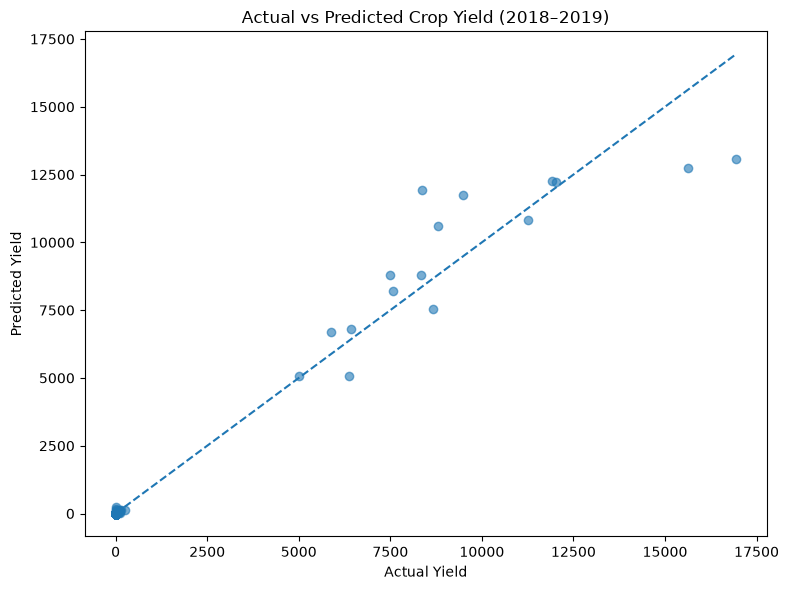

In [40]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    results["Actual_Yield"],
    results["Predicted_Yield"],
    alpha=0.6
)

# Ideal predictions lie on this line
max_value = max(
    results["Actual_Yield"].max(),
    results["Predicted_Yield"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Crop Yield (2018–2019)")
plt.tight_layout()
plt.show()


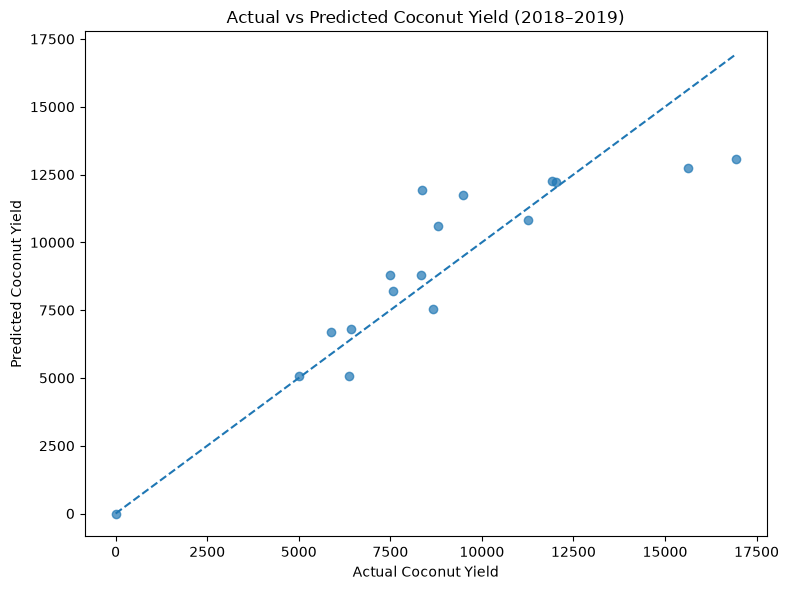

In [41]:

coconut_results = results[results["Crop"] == "Coconut"]

plt.figure(figsize=(8, 6))

plt.scatter(
    coconut_results["Actual_Yield"],
    coconut_results["Predicted_Yield"],
    alpha=0.7
)

min_value = min(
    coconut_results["Actual_Yield"].min(),
    coconut_results["Predicted_Yield"].min()
)

max_value = max(
    coconut_results["Actual_Yield"].max(),
    coconut_results["Predicted_Yield"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Coconut Yield")
plt.ylabel("Predicted Coconut Yield")
plt.title("Actual vs Predicted Coconut Yield (2018–2019)")
plt.tight_layout()
plt.show()


In [42]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Transform the target for training
y_train_log = np.log1p(y_train)

# Reuse the preprocessing setup, but train a new model
log_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

log_model.fit(X_train, y_train_log)

# Predict in log space, then convert back to original yield units
y_pred_log = log_model.predict(X_test)
y_pred_log = np.maximum(y_pred_log, 0)
y_pred_log_original = np.expm1(y_pred_log)

print("Log-transformed target model trained!")


Log-transformed target model trained!


In [43]:

# Evaluate predictions in the original yield units
log_mae = mean_absolute_error(y_test, y_pred_log_original)
log_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_log_original)
)
log_r2 = r2_score(y_test, y_pred_log_original)

print("Log-Transformed Model — Test Results")
print("-" * 40)
print(f"MAE  : {log_mae:.4f}")
print(f"RMSE : {log_rmse:.4f}")
print(f"R²   : {log_r2:.4f}")

print("\nBaseline Model — Test Results")
print("-" * 40)
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")


Log-Transformed Model — Test Results
----------------------------------------
MAE  : 10.6382
RMSE : 150.3480
R²   : 0.9692

Baseline Model — Test Results
----------------------------------------
MAE  : 11.2250
RMSE : 154.4333
R²   : 0.9675


In [44]:

# Baseline predictions vs. log-transformed predictions for Coconut
coconut_mask = X_test["Crop"] == "Coconut"

coconut_comparison = pd.DataFrame({
    "Actual_Yield": y_test.loc[coconut_mask],
    "Baseline_Prediction": final_model.predict(
        X_test.loc[coconut_mask]
    ),
    "Log_Model_Prediction": y_pred_log_original[
        coconut_mask.to_numpy()
    ]
})

coconut_comparison["Baseline_Error"] = abs(
    coconut_comparison["Actual_Yield"]
    - coconut_comparison["Baseline_Prediction"]
)

coconut_comparison["Log_Model_Error"] = abs(
    coconut_comparison["Actual_Yield"]
    - coconut_comparison["Log_Model_Prediction"]
)

display(coconut_comparison.round(4))

print("\nCoconut MAE comparison")
print("Baseline:", round(coconut_comparison["Baseline_Error"].mean(), 4))
print("Log model:", round(coconut_comparison["Log_Model_Error"].mean(), 4))


,Actual_Yield,Baseline_Prediction,Log_Model_Prediction,Baseline_Error,Log_Model_Error
5425,15636.6323,12727.0028,13071.5329,2909.6295,2565.0994
5491,8363.1550,11912.5432,11936.6005,3549.3882,3573.4455
5531,8664.6867,7526.7866,7272.3154,1137.9000,1392.3713
5598,5013.6900,5057.3023,5044.5253,43.6123,30.8353
5616,7502.4880,8799.4738,8566.1208,1296.9858,1063.6328
5682,6426.8200,6788.1226,6750.2862,361.3026,323.4662
5714,11263.8300,10807.2986,10762.8073,456.5314,501.0227
5771,16935.0585,13061.9047,13085.5565,3873.1538,3849.5020
5838,9474.6250,11746.1230,11766.9485,2271.4980,2292.3235
5877,7582.2878,8200.4945,8107.8116,618.2067,525.5238



Coconut MAE comparison
Baseline: 1262.0479
Log model: 1208.1584


In [45]:

print("Coconut MAE comparison")
print("-" * 35)

print(
    "Baseline MAE:",
    round(coconut_comparison["Baseline_Error"].mean(), 4)
)

print(
    "Log model MAE:",
    round(coconut_comparison["Log_Model_Error"].mean(), 4)
)

improvement = (
    coconut_comparison["Baseline_Error"].mean()
    - coconut_comparison["Log_Model_Error"].mean()
)

print("MAE improvement:", round(improvement, 4))



Coconut MAE comparison
-----------------------------------
Baseline MAE: 1262.0479
Log model MAE: 1208.1584
MAE improvement: 53.8895


In [46]:

# Build predictions for both models on the same test set
baseline_results = results.copy()

baseline_results["Baseline_Prediction"] = final_model.predict(X_test)
baseline_results["Log_Prediction"] = y_pred_log_original

baseline_results["Baseline_Error"] = abs(
    y_test - baseline_results["Baseline_Prediction"]
)

baseline_results["Log_Error"] = abs(
    y_test - baseline_results["Log_Prediction"]
)

crop_comparison = baseline_results.groupby("Crop").agg(
    Records=("Actual_Yield", "size"),
    Baseline_MAE=("Baseline_Error", "mean"),
    Log_MAE=("Log_Error", "mean")
)

crop_comparison["MAE_Improvement"] = (
    crop_comparison["Baseline_MAE"]
    - crop_comparison["Log_MAE"]
)

crop_comparison = crop_comparison.sort_values(
    "MAE_Improvement",
    ascending=False
)

display(crop_comparison.head(10).round(4))


,Records,Baseline_MAE,Log_MAE,MAE_Improvement
Crop,,,,
Coconut,17,1262.0479,1208.1584,53.8895
Maize,101,4.0024,0.9577,3.0448
Banana,23,11.6203,10.5859,1.0344
Cashewnut,16,1.0670,0.1587,0.9083
Castor seed,33,1.0705,0.1710,0.8995
Oilseeds total,4,1.3984,0.9436,0.4548
Sunflower,51,0.7320,0.2802,0.4518
Mesta,21,1.9749,1.6197,0.3552
Black pepper,15,0.5693,0.2296,0.3397


In [47]:

improved_crops = (
    crop_comparison["MAE_Improvement"] > 0
).sum()

worsened_crops = (
    crop_comparison["MAE_Improvement"] < 0
).sum()

unchanged_crops = (
    crop_comparison["MAE_Improvement"] == 0
).sum()

print("Total crops evaluated:", len(crop_comparison))
print("Crops improved:", improved_crops)
print("Crops worsened:", worsened_crops)
print("Crops unchanged:", unchanged_crops)

print("\nLargest MAE regressions:")
display(
    crop_comparison.sort_values("MAE_Improvement").head(5).round(4)
)


Total crops evaluated: 55
Crops improved: 29
Crops worsened: 26
Crops unchanged: 0

Largest MAE regressions:


,Records,Baseline_MAE,Log_MAE,MAE_Improvement
Crop,,,,
Onion,54,9.1138,10.0531,-0.9392
Sugarcane,52,6.2551,6.9361,-0.6810
Dry chillies,39,1.2361,1.4359,-0.1998
Sweet potato,33,2.9115,3.0750,-0.1635
Tapioca,22,2.5481,2.6960,-0.1480


In [48]:

model_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Baseline": [mae, rmse, r2],
    "Log_Transformed": [log_mae, log_rmse, log_r2]
})

model_comparison["Change"] = (
    model_comparison["Log_Transformed"]
    - model_comparison["Baseline"]
)

display(model_comparison.round(4))


,Metric,Baseline,Log_Transformed,Change
0,MAE,11.2250,10.6382,-0.5869
1,RMSE,154.4333,150.3480,-4.0853
2,R2,0.9675,0.9692,0.0017


In [49]:

import sys
from pathlib import Path

# Make the src folder importable
sys.path.insert(0, str(Path("../src").resolve()))

from crop_yield_model import train_model, predict_yield, FEATURES

# Use the same chronological split
train_mask = df["Crop_Year"] <= 2017
test_mask = df["Crop_Year"].between(2018, 2019)

train_df = df.loc[train_mask]
test_df = df.loc[test_mask]

X_test_final = test_df[FEATURES]
y_test_final = test_df["Yield"]

# Train the reusable model on earlier years only
reusable_model = train_model(train_df)

# Predict on later years
y_pred_final = predict_yield(reusable_model, X_test_final)

print("Reusable model trained and predictions generated!")
print("Training records:", len(train_df))
print("Testing records:", len(test_df))


Reusable model trained and predictions generated!
Training records: 17510
Testing records: 2142


In [50]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_final = mean_absolute_error(y_test_final, y_pred_final)
rmse_final = np.sqrt(
    mean_squared_error(y_test_final, y_pred_final)
)
r2_final = r2_score(y_test_final, y_pred_final)

print("Reusable Model Evaluation (2018–2019)")
print("-" * 40)
print(f"MAE  : {mae_final:.4f}")
print(f"RMSE : {rmse_final:.4f}")
print(f"R²   : {r2_final:.4f}")

print("\nPrevious log-model results")
print(f"MAE  : {log_mae:.4f}")
print(f"RMSE : {log_rmse:.4f}")
print(f"R²   : {log_r2:.4f}")


Reusable Model Evaluation (2018–2019)
----------------------------------------
MAE  : 10.6382
RMSE : 150.3480
R²   : 0.9692

Previous log-model results
MAE  : 10.6382
RMSE : 150.3480
R²   : 0.9692


In [51]:

import joblib
from pathlib import Path

# Save the trained model
model_path = Path("../models/crop_yield_model.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(reusable_model, model_path)

print("Model saved successfully!")
print("Saved to:", model_path.resolve())


Model saved successfully!
Saved to: C:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\models\crop_yield_model.joblib


In [52]:

import joblib
import numpy as np

# Load the saved model
loaded_model = joblib.load(model_path)

# Predict using the loaded model
loaded_predictions = predict_yield(
    loaded_model,
    X_test_final
)

# Compare with predictions before saving
max_difference = np.max(
    np.abs(y_pred_final - loaded_predictions)
)

print("Saved model loaded successfully!")
print("Maximum prediction difference:", max_difference)
print("Predictions match:", np.allclose(
    y_pred_final,
    loaded_predictions
))


Saved model loaded successfully!
Maximum prediction difference: 4.3655745685100555e-11
Predictions match: True
